# 03 — Model Comparison and Final Evaluation

**Project:** Bangladeshi Freshwater Fish Image Classification Using CNN and Transfer Learning
**Dataset:** BFF-15 (15 classes)
**Owner:** Swapnil Santosh Akhade

## Purpose

Read the logs and metrics produced by:

- `01_custom_cnn.ipynb` (Vivek)
- `02_transfer_learning.ipynb` (Mansi)

and produce:

1. Side-by-side training curves (accuracy and loss).
2. A comparison table of test-set metrics.
3. Confusion matrices side by side.
4. A short written comparison, kept separate from the published paper's results.

## What this notebook needs

- `custom_cnn/logs/training_log.csv`
- `custom_cnn/metrics/final_metrics.json`
- `custom_cnn/metrics/confusion_matrix.csv`
- `custom_cnn/metrics/test_predictions.csv`
- `custom_cnn/plots/confusion_matrix.png`
- `transfer_learning/logs/training_log.csv`
- `transfer_learning/metrics/final_metrics.json`
- `transfer_learning/metrics/confusion_matrix.csv`
- `transfer_learning/metrics/test_predictions.csv`
- `transfer_learning/plots/confusion_matrix.png`

If any are missing, both teammates haven't finished yet.

In [1]:
import sys, json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

sys.path.append(str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

# PROJECT_ROOT is anchored to data_utils.__file__ so this notebook reads the same
# folders whether it runs locally, in VS Code or in Colab.
from data_utils import PROJECT_ROOT

CNN_DIR = PROJECT_ROOT / "custom_cnn"
TL_DIR  = PROJECT_ROOT / "transfer_learning"
OUT_DIR = PROJECT_ROOT / "outputs" / "comparison"
OUT_DIR.mkdir(parents=True, exist_ok=True)

required = [
    CNN_DIR / "logs" / "training_log.csv",
    CNN_DIR / "metrics" / "final_metrics.json",
    CNN_DIR / "metrics" / "confusion_matrix.csv",
    CNN_DIR / "metrics" / "test_predictions.csv",
    TL_DIR  / "logs" / "training_log.csv",
    TL_DIR  / "metrics" / "final_metrics.json",
    TL_DIR  / "metrics" / "confusion_matrix.csv",
    TL_DIR  / "metrics" / "test_predictions.csv",
]

missing = [str(p) for p in required if not p.exists()]
if missing:
    print("Missing artifacts:")
    for m in missing:
        print(" -", m)
    raise SystemExit("Both teammates must finish training first.")

print("All artifacts present.")


All artifacts present.


In [2]:
cnn_log = pd.read_csv(CNN_DIR / "logs" / "training_log.csv")
tl_log  = pd.read_csv(TL_DIR  / "logs" / "training_log.csv")

with open(CNN_DIR / "metrics" / "final_metrics.json") as f:
    cnn_metrics = json.load(f)
with open(TL_DIR / "metrics" / "final_metrics.json") as f:
    tl_metrics = json.load(f)

cnn_cm = pd.read_csv(CNN_DIR / "metrics" / "confusion_matrix.csv", index_col=0)
tl_cm  = pd.read_csv(TL_DIR  / "metrics" / "confusion_matrix.csv", index_col=0)

print("CNN epochs:", len(cnn_log))
print("TL  epochs:", len(tl_log))

CNN epochs: 20
TL  epochs: 29


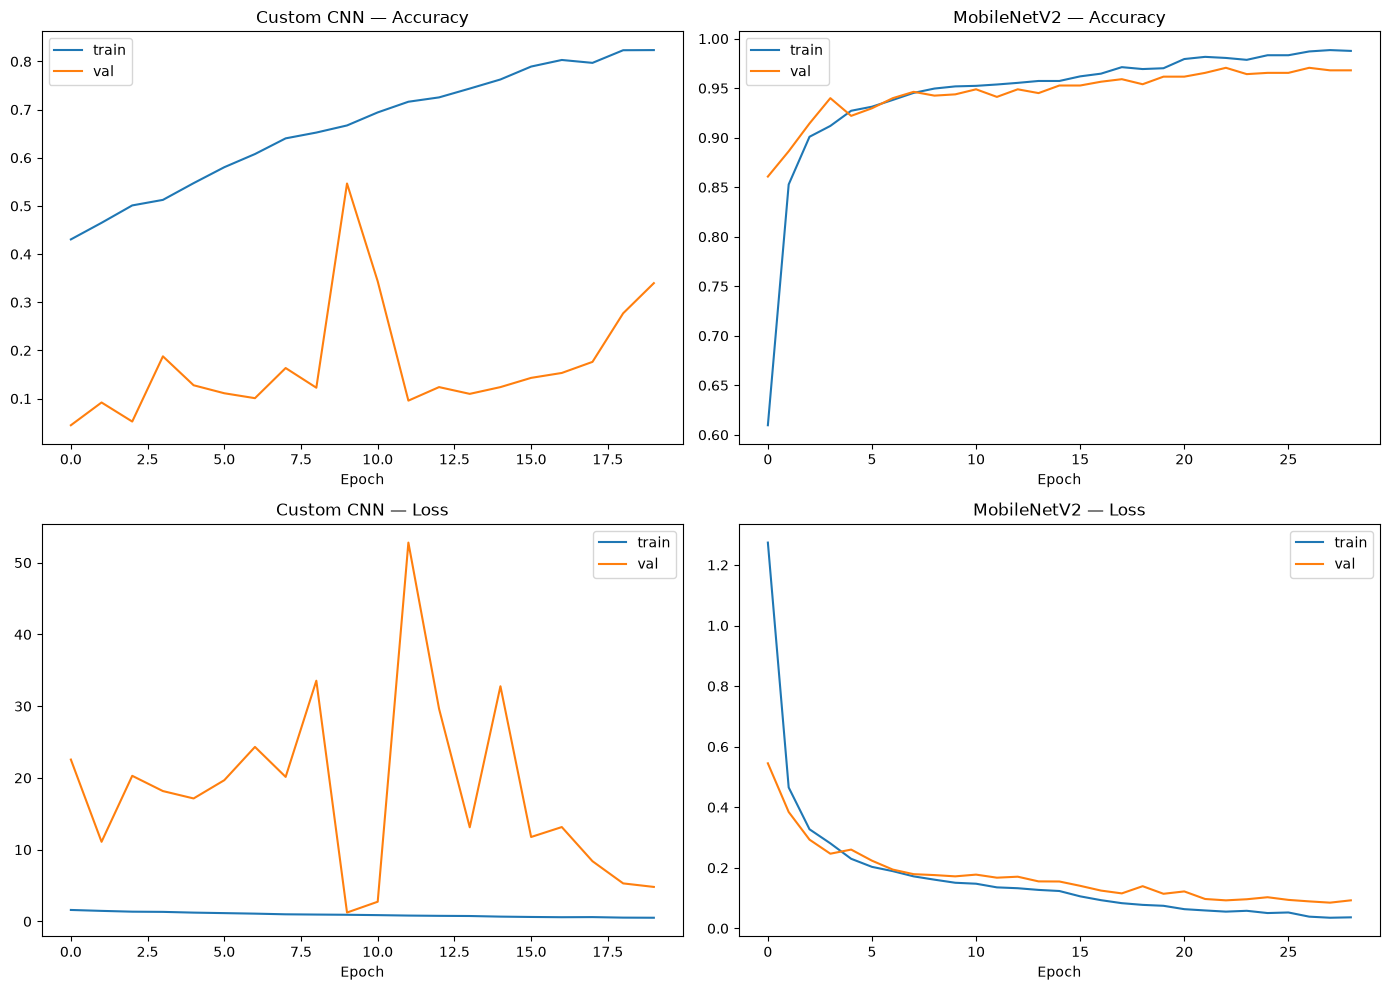

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].plot(cnn_log["epoch"], cnn_log["accuracy"], label="train")
axes[0, 0].plot(cnn_log["epoch"], cnn_log["val_accuracy"], label="val")
axes[0, 0].set_title("Custom CNN — Accuracy")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].legend()

axes[0, 1].plot(tl_log["epoch"], tl_log["accuracy"], label="train")
axes[0, 1].plot(tl_log["epoch"], tl_log["val_accuracy"], label="val")
axes[0, 1].set_title(f"{tl_metrics['base_model']} — Accuracy")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].legend()

axes[1, 0].plot(cnn_log["epoch"], cnn_log["loss"], label="train")
axes[1, 0].plot(cnn_log["epoch"], cnn_log["val_loss"], label="val")
axes[1, 0].set_title("Custom CNN — Loss")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].legend()

axes[1, 1].plot(tl_log["epoch"], tl_log["loss"], label="train")
axes[1, 1].plot(tl_log["epoch"], tl_log["val_loss"], label="val")
axes[1, 1].set_title(f"{tl_metrics['base_model']} — Loss")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].legend()

plt.tight_layout()
plt.savefig(str(OUT_DIR / "curves_side_by_side.png"), dpi=150)
plt.show()

In [4]:
# .get() with a default: a metric added later (top-5, AUC) must not turn into a
# KeyError if one teammate's notebook predates it.
g = lambda m, k: m.get(k, float("nan"))

rows = [
    ("Accuracy",              g(cnn_metrics, "test_accuracy"),            g(tl_metrics, "test_accuracy")),
    ("Top-5 accuracy",        g(cnn_metrics, "test_top5_accuracy"),       g(tl_metrics, "test_top5_accuracy")),
    ("ROC-AUC (ovr)",         g(cnn_metrics, "test_roc_auc_ovr"),         g(tl_metrics, "test_roc_auc_ovr")),
    ("Precision (macro)",     g(cnn_metrics, "test_precision_macro"),     g(tl_metrics, "test_precision_macro")),
    ("Recall (macro)",        g(cnn_metrics, "test_recall_macro"),        g(tl_metrics, "test_recall_macro")),
    ("F1 (macro)",            g(cnn_metrics, "test_f1_macro"),            g(tl_metrics, "test_f1_macro")),
    ("Precision (weighted)",  g(cnn_metrics, "test_precision_weighted"),  g(tl_metrics, "test_precision_weighted")),
    ("Recall (weighted)",     g(cnn_metrics, "test_recall_weighted"),     g(tl_metrics, "test_recall_weighted")),
    ("F1 (weighted)",         g(cnn_metrics, "test_f1_weighted"),         g(tl_metrics, "test_f1_weighted")),
    ("Epochs ran",            g(cnn_metrics, "epochs_ran"),               g(tl_metrics, "epochs_ran")),
    ("Train minutes",         round(g(cnn_metrics, "train_seconds") / 60, 1),
                              round(g(tl_metrics, "train_seconds") / 60, 1)),
    ("Total params",          g(cnn_metrics, "total_params"),             g(tl_metrics, "total_params")),
    ("Trainable params",      g(cnn_metrics, "trainable_params"),         g(tl_metrics, "trainable_params")),
]

df = pd.DataFrame(rows, columns=["Metric", "Custom CNN", f"TL ({tl_metrics['base_model']})"])
df["\u0394 (TL - CNN)"] = df[f"TL ({tl_metrics['base_model']})"] - df["Custom CNN"]

print(df.to_string(index=False))
df.to_csv(OUT_DIR / "comparison_table.csv", index=False)
print()
print("Saved:", OUT_DIR / "comparison_table.csv")


              Metric   Custom CNN  TL (MobileNetV2)  Δ (TL - CNN)
            Accuracy 5.625000e-01      9.757653e-01  4.132653e-01
      Top-5 accuracy 9.604592e-01      1.000000e+00  3.954082e-02
       ROC-AUC (ovr) 9.509575e-01      9.993619e-01  4.840434e-02
   Precision (macro) 6.462737e-01      9.768171e-01  3.305435e-01
      Recall (macro) 5.667915e-01      9.763005e-01  4.095090e-01
          F1 (macro) 5.524650e-01      9.763996e-01  4.239346e-01
Precision (weighted) 6.354973e-01      9.760028e-01  3.405055e-01
   Recall (weighted) 5.625000e-01      9.757653e-01  4.132653e-01
       F1 (weighted) 5.443757e-01      9.757021e-01  4.313264e-01
          Epochs ran 4.000000e+01      1.500000e+01 -2.500000e+01
       Train minutes 1.920000e+01      1.970000e+01  5.000000e-01
        Total params 1.209967e+06      2.277199e+06  1.067232e+06
    Trainable params 1.208047e+06      1.529935e+06  3.218880e+05

Saved: D:\GenAI\Practical 1\outputs\comparison\comparison_table.csv


## Is the gap real? McNemar's test

Both models were evaluated on the *same* 784 test images, so the scores are
paired. A 1-2 point accuracy gap on a test set this small is often just noise.
McNemar's test compares only the images one model got right and the other got
wrong, and says whether the difference is statistically significant.


In [5]:
from scipy.stats import chi2

cnn_p = pd.read_csv(CNN_DIR / "metrics" / "test_predictions.csv")
tl_p  = pd.read_csv(TL_DIR  / "metrics" / "test_predictions.csv")

# both files list the frozen split in the same order; assert rather than assume
assert (cnn_p["filepath"].values == tl_p["filepath"].values).all(), "prediction files are not aligned"

ok_cnn, ok_tl = cnn_p["correct"].values, tl_p["correct"].values
b = int(((ok_cnn == 1) & (ok_tl == 0)).sum())   # CNN right, TL wrong
c = int(((ok_cnn == 0) & (ok_tl == 1)).sum())   # CNN wrong, TL right
n = b + c

if n == 0:
    print("The two models make identical mistakes on every test image; McNemar is undefined.")
else:
    chi2_stat = (abs(b - c) - 1) ** 2 / n       # continuity-corrected
    p_value = float(chi2.sf(chi2_stat, 1))
    print(f"CNN-only-correct b={b} | TL-only-correct c={c} | discordant n={n}")
    print(f"McNemar chi2 (continuity corrected) = {chi2_stat:.3f}, p = {p_value:.4f}")
    print("=> statistically significant at alpha=0.05" if p_value < 0.05
          else "=> NOT significant at alpha=0.05: the accuracy gap is within noise for this test-set size")
    print(f"Net win: {'TL' if c > b else 'CNN'} by {abs(c - b)} images "
          f"({abs(c - b) / len(ok_cnn) * 100:.1f} percentage points)")

json.dump({"b_cnn_only": b, "c_tl_only": c, "chi2": (abs(b - c) - 1) ** 2 / n if n else None,
           "p_value": p_value if n else None},
          open(OUT_DIR / "mcnemar.json", "w"), indent=2)


CNN-only-correct b=3 | TL-only-correct c=327 | discordant n=330
McNemar chi2 (continuity corrected) = 316.148, p = 0.0000
=> statistically significant at alpha=0.05
Net win: TL by 324 images (41.3 percentage points)


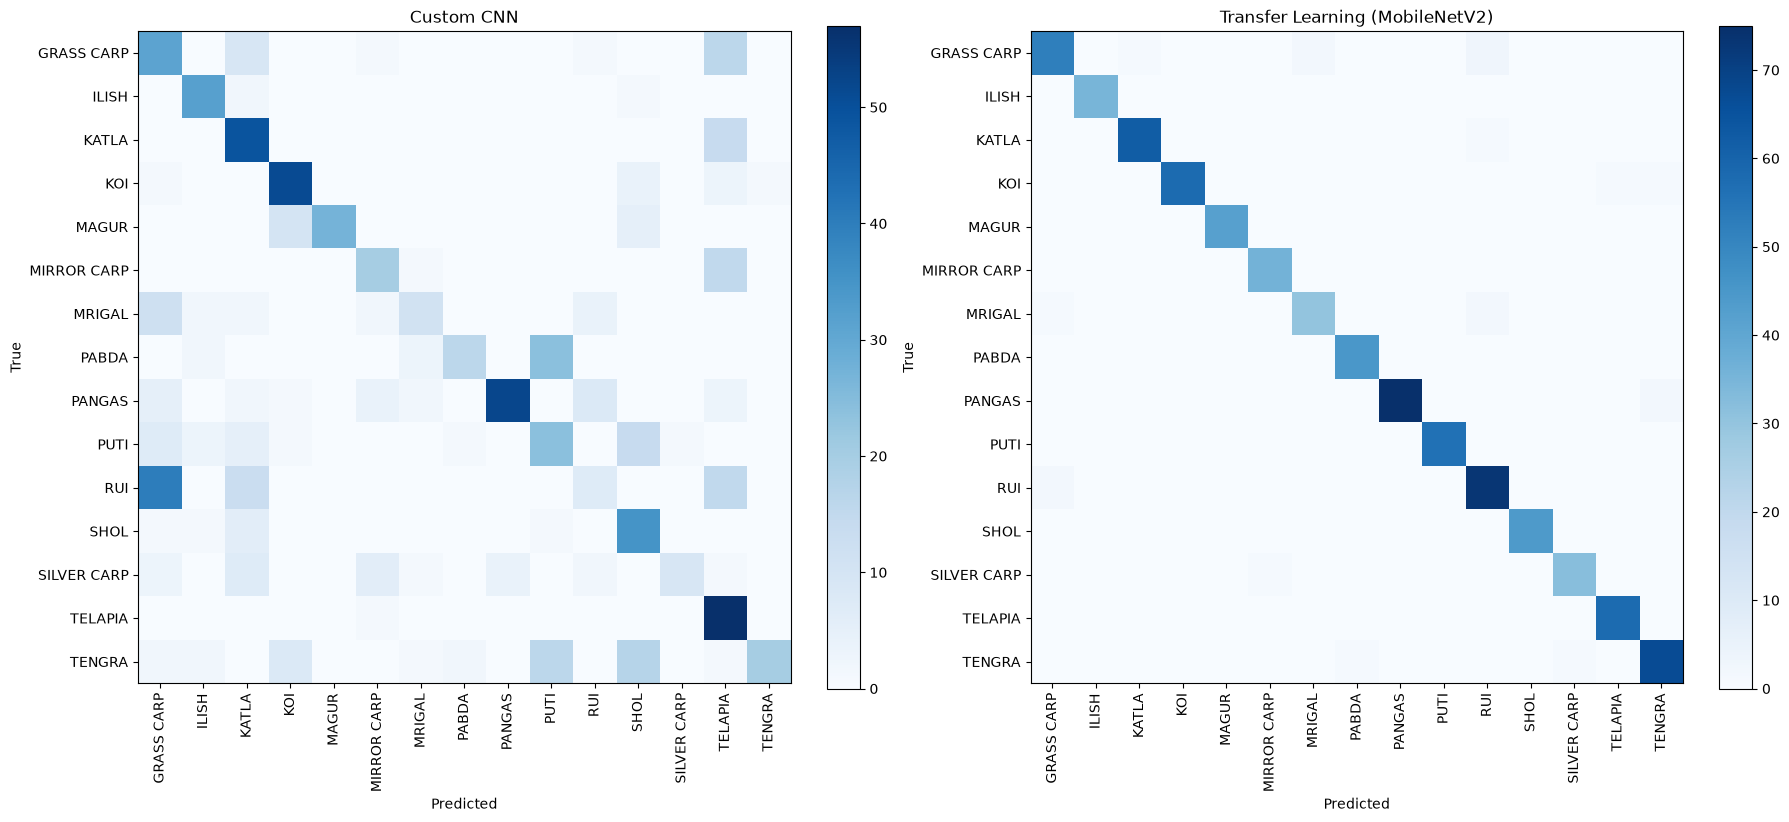

In [6]:
cm_cnn = cnn_cm.values
cm_tl  = tl_cm.values
labels = list(cnn_cm.index)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for ax, cm, title in [
    (axes[0], cm_cnn, "Custom CNN"),
    (axes[1], cm_tl,  f"Transfer Learning ({tl_metrics['base_model']})"),
]:
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_xticks(range(len(labels)))
    ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=90)
    ax.set_yticklabels(labels)
    plt.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.savefig(str(OUT_DIR / "confusion_matrices_side_by_side.png"), dpi=150)
plt.show()

## Written comparison

Fill in after looking at the table and the confusion matrices.

Things to discuss:

- Which model performed better on the test set, and by how much.
- Which classes are hardest for both models (rows with many off-diagonal entries).
- Which classes one model handles but the other struggles with.
- Whether the transfer-learning model overfit, underfit, or generalized well
  (look at train vs val curves).
- Whether the custom CNN had enough capacity or training time.
- Whether the class imbalance affected either model.

**Do not** claim we reproduced the reference paper. The paper uses a different
dataset (8 species), different models, and a different augmentation strategy.
Our results are an adapted comparison, not a reproduction.

## Reference paper vs our experiment

| Item | Reference paper | This practical |
|---|---|---|
| Dataset | 8 species | BFF-15, 15 classes |
| Train/test split | Not identical to ours | 70 / 15 / 15 stratified, seed 42 |
| Models | InceptionV3, Xception, DenseNet, InceptionResNetV2, ResNet152V2, hybrid CNN–ConvLSTM | One from-scratch CNN + one fine-tuned pretrained model |
| Reported top accuracy | To be verified from the paper | See table above |

Both rows are deliberately separated. Do not merge them.

In [7]:
summary = {
    "custom_cnn": {
        "accuracy": cnn_metrics["test_accuracy"],
        "f1_macro": cnn_metrics["test_f1_macro"],
        "f1_weighted": cnn_metrics["test_f1_weighted"],
        "epochs_ran": cnn_metrics["epochs_ran"],
    },
    "transfer_learning": {
        "base_model": tl_metrics["base_model"],
        "accuracy": tl_metrics["test_accuracy"],
        "f1_macro": tl_metrics["test_f1_macro"],
        "f1_weighted": tl_metrics["test_f1_weighted"],
        "epochs_ran": tl_metrics["epochs_ran"],
    },
}

with open(OUT_DIR / "final_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))

{
  "custom_cnn": {
    "accuracy": 0.5625,
    "f1_macro": 0.5524649591797286,
    "f1_weighted": 0.5443756721171454,
    "epochs_ran": 40
  },
  "transfer_learning": {
    "base_model": "MobileNetV2",
    "accuracy": 0.9757653061224489,
    "f1_macro": 0.9763995924853269,
    "f1_weighted": 0.9757021191683086,
    "epochs_ran": 15
  }
}


## Export for the results website
Creates `outputs/website/results.json` with metrics, training curves, per-class scores and confusion matrices for both models.

In [8]:
# ---- Export everything the results website needs into ONE file: results.json ----
import json
WEB_DIR = PROJECT_ROOT / "outputs" / "website"
WEB_DIR.mkdir(parents=True, exist_ok=True)

def pack(model_dir, label):
    log = pd.read_csv(model_dir / "logs" / "training_log.csv")
    with open(model_dir / "metrics" / "final_metrics.json") as f:
        m = json.load(f)
    cm = pd.read_csv(model_dir / "metrics" / "confusion_matrix.csv", index_col=0)
    return {
        "label": label,
        "base_model": m["base_model"],
        "metrics": {k: v for k, v in m.items() if k != "per_class"},
        "per_class": m["per_class"],
        "history": {c: log[c].round(5).tolist() for c in ["epoch", "accuracy", "val_accuracy", "loss", "val_loss"]},
        "confusion_matrix": cm.values.tolist(),
    }

with open(CNN_DIR / "metrics" / "pipeline_config.json") as f:
    cfg = json.load(f)

results = {
    "project": "Bangladeshi Freshwater Fish Image Classification Using CNN and Transfer Learning",
    "team": ["Swapnil Santosh Akhade", "Mansi Somani", "Vivek Singh"],
    "dataset": {
        "name": "BFF-15 (Bangladeshi Freshwater Fish Image Dataset)",
        "license": "CC BY 4.0",
        "source": "https://www.kaggle.com/datasets/theshahidul/bangladeshi-freshwater-fish-image-dataset-bff-15",
        "classes": cfg["class_names"],
        "img_size": cfg["img_size"],
        "split": {"train": cfg["train_size"], "val": cfg["val_size"], "test": cfg["test_size"]},
        "augmentation": cfg["augmentation"],
    },
    "models": {
        "custom_cnn": pack(CNN_DIR, "Custom CNN (from scratch)"),
        "transfer_learning": pack(TL_DIR, "Transfer learning (fine-tuned)"),
    },
}
with open(WEB_DIR / "results.json", "w") as f:
    json.dump(results, f, indent=2)
print("Saved:", WEB_DIR / "results.json")

Saved: D:\GenAI\Practical 1\outputs\website\results.json
